# B2B-платформа продуктовой аналитики и ETL-пайплайн для eCommerce

`https://github.com/ion04/analytics-rees46-marketplace`

## 1. Продукт

### Что делаем
Мы разрабатываем **B2B-платформу для продуктовой и маркетинговой аналитики e-commerce** (Data-as-a-Service). 
Сервис собирает сырые логи поведенческих событий (`view → cart → purchase`), очищает их от технического шума и дубликатов, и в автоматическом режиме строит витрины данных (Data Marts) для расчета ключевых бизнес-метрик: выручки, когортного удержания (Retention) и юнит-экономики каналов (LTV/CAC).

### Для кого
| Сегмент | Роль | Что получает |
|:--|:--|:--|
| Мультикатегорийные интернет-магазины | Продакт-менеджер, Маркетолог | Готовые дашборды в реальном времени (Superset) без написания SQL |
| Команда аналитики магазина | Data Analyst, Data Engineer | Надежный ETL-пайплайн (ClickHouse) с уже очищенными (Medallion Architecture) данными |

### Проблема
- Логи веб-аналитики содержат до 15% "мусора": боты, тестовые аккаунты, дубликаты событий (ретраи).
- Без очистки этих данных метрики (Retention, LTV, Выручка) завышаются, и бизнес принимает неверные решения.
- Построение аналитики с нуля требует времени и компетенций Data Engineer'а.

### Гипотеза ценности
> Если автоматизировать очистку логов (отсев ботов, дедупликация) и построить трехслойную архитектуру хранилища (Bronze → Silver → Gold), то бизнес получит **достоверные метрики юнит-экономики**, что позволит оптимизировать маркетинговый бюджет и отказаться от убыточных каналов привлечения.

### Бизнес-модель
- **B2B SaaS**: подписка по объёму обрабатываемых событий (от 10 млн событий/мес).
- **Enterprise**: внедрение на инфраструктуре клиента (On-Premise).
- *(В перспективе)* **ML-модуль**: предсказание вероятности покупки в сессии и триггерные коммуникации.

### Ключевые метрики продукта (подробно — в разделе 4)
| Уровень | Метрика |
|:--|:--|
| Бизнес (North Star) | GMV (Gross Merchandise Value) |
| Продукт | LTV/CAC по каналам, Cart Conversion Rate |
| Риск (Data Quality) | Доля нерелевантного трафика (боты + дубликаты) |

### Связь с unit-экономикой
Ценность платформы напрямую зависит от точности расчета LTV/CAC. Очистка данных от ботов (исключение «накрученного» трафика) позволяет бизнесу увидеть реальный CAC и не слить бюджет на неэффективные каналы.

---

## 2. Данные

### 2.1 Источник
**REES46 «eCommerce behavior data from multi category store»**: обезличенные логи поведенческих событий крупного мультикатегорийного интернет-магазина, опубликованные в рамках инициативы Open CDP.

| Источник | Ссылка |
|:--|:--|
| Оригинальный датасет (Kaggle) | https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store |

**Версия датасета:** <Version 8>

### 2.2 Лицензия и условия использования
Условия автора датасета (REES46 / Open CDP):
- Свободное использование в **образовательных, научных, исследовательских и демонстрационных** целях.
- При публикации кода, аналитики, книг или учебных материалов **обязательно указывать источник**: ссылки на Kaggle-датасет и на REES46 (см. выше).
- Формальный идентификатор лицензии: `Data files © Original Authors`.

**Данные в репозитории.** Полные CSV в репозиторий не включены: лицензия Kaggle (`Data files © Original Authors`) не даёт права на перепубликацию файлов, к тому же их объём превышает лимит GitHub в 100 МБ на файл. Воспроизведение — по инструкции ниже.

**Как воспроизвести данные:**
```bash
# Скачать четыре нужных месячных файла в папку data/
# (пакетная загрузка всего датасета добавит другие месяцы, и pipeline.py загрузит их тоже)
for f in 2019-Nov 2019-Dec 2020-Jan 2020-Feb; do
  kaggle datasets download -d mkechinov/ecommerce-behavior-data-from-multi-category-store -f $f.csv -p data/ --unzip
done
```
**Как развернуть инфраструктуру:**
```bash
# Запуск СУБД ClickHouse и Apache Superset
docker compose up -d        
```

**Загрузка в слой Bronze.** Создание схемы и импорт CSV (`data/*.csv` → `shop.events_raw`) выполняются следующей ячейкой. Перед импортом таблица очищается (`TRUNCATE`), поэтому шаг идемпотентен.

In [47]:
%%bash
python pipeline.py tables load


--- Запуск: tables ---
tables: ok (Bronze, Silver, Gold)

--- Запуск: load ---
loading 2019-Dec.csv
  +67,542,878 строк
loading 2019-Nov.csv
  +67,501,979 строк
loading 2020-Feb.csv
  +55,318,565 строк
loading 2020-Jan.csv
  +55,967,041 строк
events total: 246,330,463


В репозитории размещены исходный код и описание схемы данных; сами данные не хранятся.

### 2.3 Объём и период наблюдения
Приведённые показатели относятся к слою Bronze (`shop.events_raw`) до очистки. В оригинальном наборе представлены и другие месячные файлы; в работе используются четыре месяца (ноябрь 2019 г. – февраль 2020 г.).

| Параметр | Значение |
|:--|:--|
| Период | **4 месяца**: ноябрь 2019 – февраль 2020 |
| Границы времени | `2019-11-01 00:00:00 UTC` – `2020-02-29 23:59:59 UTC` |
| Формат | 4 месячных CSV-файла |
| Число строк | `246 330 463` |
| Уникальных пользователей | `10 723 863` |
| Уникальных сессий | `56 293 798` |
| Уникальных категорий | `1270` |
| Объём | `9,5 ГБ` |

### 2.4 Схема данных
Типы приведены для слоя Bronze (`shop.events_raw`, DDL — `pipeline.py`).

| Поле | Семантика | Тип в `events_raw` | Комментарий |
|:--|:--|:--|:--|
| `event_time` | Время действия на платформе | `DateTime('UTC')` | UTC |
| `event_type` | Тип события | `LowCardinality(String)` | `view` (просмотр), `cart` (добавление в корзину), `purchase` (покупка) |
| `product_id` | Идентификатор товара | `UInt64` | Уникальный идентификатор в каталоге |
| `category_id` | Идентификатор категории | `UInt64` | Уникальный идентификатор категории |
| `category_code` | Иерархия категории (текстовый путь) | `LowCardinality(Nullable(String))` | Пустые строки преобразуются в `NULL` |
| `brand` | Торговая марка | `LowCardinality(Nullable(String))` | Пустые строки преобразуются в `NULL` |
| `price` | Стоимость товара в событии | `Decimal64(2)` | Исходно `Float64`, приводится при загрузке |
| `user_id` | Идентификатор пользователя | `UInt64` | Обезличенный |
| `user_session` | Идентификатор сессии | `Nullable(UUID)` | Некорректные значения преобразуются в `NULL` |

### 2.5 Ограничения набора данных
- Данные **обезличены**: отсутствуют демографические признаки, канал привлечения, тип устройства и местоположение.
- Отсутствует информация о **скидках, акциях и коммуникациях**.
- Набор относится к одному магазину; перенос выводов на другие предметные области требует дополнительной проверки.
- Отсутствуют сведения о доставке и возвратах.
- Поле `price` отражает цену товара в момент события.
- Идентификатор сессии `user_session` формируется источником (REES46); правила его формирования неизвестны.
- Окно наблюдения составляет 4 месяца, поэтому LTV оценивается только за этот срок; кроме того, ноябрьская когорта включает пользователей, привлечённых до начала окна (левое цензурирование).
- Канал привлечения и маркетинговые расходы в наборе отсутствуют и **генерируются синтетически** в конвейере (`pipeline.py`, `SEED=26`).

### 2.6 Обоснование пригодности набора данных
1. **Соответствие задаче.** Наличие воронки `view → cart → purchase` и идентификатора сессии позволяет сформировать целевую переменную «покупка в сессии» и поведенческие признаки.
2. **Объём.** Миллионы событий и сессий обеспечивают статистическую мощность, возможность временной валидации и анализа сегментов.
3. **Реальный характер данных.** Присутствуют естественный шум, дисбаланс классов и длинный хвост распределения товаров.
4. **Полнота каталога.** Категории, бренды и цены позволяют строить признаки товаров и корзины.
5. **Протяжённость периода.** Четыре месяца охватывают недельную сезонность и предпраздничный период (ноябрь–декабрь), а обучение и проверку можно разнести во времени (январь–февраль).
6. **Условия использования.** Лицензия допускает применение в образовательных и исследовательских целях при указании источника.

**Не покрывается набором данных:** причинный эффект скидок и рассылок, признаки устройства и канала, данные о возвратах.

### 2.7 Верификация качества данных

Проверке подвергаются полнота (пропуски), уникальность (дубликаты), корректность временных границ, аномальные значения цены и аномальная активность пользователей. Все проверки выполняются над слоем Bronze (`shop.events_raw`); принятые решения по очистке сведены в таблицу п. 2.8.

#### 2.7.1 Полнота данных (пропуски)

In [48]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT count() AS total_rows,
        round(avg(isNull(user_session))*100, 8) AS null_user_pct,
        round(avg(isNull(brand))*100, 4) AS null_brand_pct,
        round(avg(isNull(category_code))*100, 4) AS null_category_code_pct,
        countIf(empty(event_type)) AS empty_event_type
    FROM shop.events_raw
    FORMAT Vertical;
"

Row 1:
──────
total_rows:             246330463 -- 246.33 million
null_user_pct:          0.00002598
null_brand_pct:         13.1759
null_category_code_pct: 15.8168
empty_event_type:       0


#### 2.7.2 Дубликаты событий

Дубликатом считается строка, совпадающая с другой по ключу `(event_type, user_id, event_time, product_id, user_session)`.

In [49]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        count() AS unique_events,
        sum(c) - count() AS exact_duplicates
    FROM (
        SELECT count() AS c
        FROM shop.events_raw
        GROUP BY event_type, user_id, event_time, product_id, user_session
    )
    SETTINGS optimize_aggregation_in_order = 1, max_threads = 3,
             max_bytes_before_external_group_by = 3500000000
    FORMAT PrettyCompact;
"

   ┌─unique_events─┬─exact_duplicates─┐
1. │     245276299 │          1054164 │ -- 1.05 million
   └───────────────┴──────────────────┘


#### 2.7.3 Временны́е границы

Ожидаемое число календарных дней с событиями — 121 (ноябрь — 30, декабрь — 31, январь — 31, февраль — 29). Если `days_with_events` меньше `days_expected`, в данных присутствуют пропущенные дни.

In [44]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        min(event_time) AS first_date,
        max(event_time) AS last_date,
        uniqExact(toDate(event_time)) AS days_with_events,
        dateDiff('day', min(event_time), max(event_time)) + 1 AS days_expected
    FROM shop.events_raw
    FORMAT Vertical;
"

Row 1:
──────
first_date:       2019-11-01 00:00:00
last_date:        2020-02-29 23:59:59
days_with_events: 121
days_expected:    121


#### 2.7.4 Аномальные значения цены

Помимо квантилей распределения рассматриваются минимум, максимум, 99,9-й перцентиль и число событий с `price <= 0`.

In [14]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        event_type,
        count() AS events,
        countIf(price <= 0) AS price_le_0,
        min(price) AS min_price,
        quantile(0.025)(price) AS q2_5_price,
        median(price) AS median_price,
        quantile(0.975)(price) AS q97_5_price,
        quantile(0.999)(price) AS q99_9_price,
        max(price) AS max_price
    FROM shop.events_raw
    GROUP BY event_type
    FORMAT PrettyCompact;
"

   ┌─event_type─┬────events─┬─price_le_0─┬─min_price─┬─q2_5_price─┬─median_price─┬─q97_5_price─┬─q99_9_price─┬─max_price─┐
1. │ cart       │  11950550 │      10343 │         0 │       9.49 │       168.82 │     1235.38 │     2201.31 │   2574.07 │
2. │ view       │ 230265631 │     504450 │         0 │       7.72 │       166.14 │     1305.83 │     2565.61 │   2574.07 │
3. │ purchase   │   4114282 │          0 │      0.77 │      12.79 │       179.93 │     1302.45 │     2096.77 │   2574.07 │
   └────────────┴───────────┴────────────┴───────────┴────────────┴──────────────┴─────────────┴─────────────┴───────────┘


#### 2.7.5 Аномально активные пользователи (боты, тестовые аккаунты)

В наборе REES46 отсутствует признак `is_bot`, поэтому аномальные учётные записи выявляются по поведенческим признакам. Применяются два правила, реализованные в слое Silver (`pipeline.py`, шаг `silver`):

1. **Аномальная суточная частота** (`high_daily_frequency`): более 1000 событий одного пользователя за календарный день (UTC). Человек физически не способен генерировать столь интенсивный поток действий; значения порядка тысяч событий в сутки (см. выдачу первой ячейки ниже) указывают на автоматизированный источник.
2. **Нечеловеческая скорость сессии** (`inhuman_session_speed`): более 50 событий в одной сессии при её длительности менее 60 секунд.


Пороговые значения в запросах ниже совпадают с порогами, применяемыми в `pipeline.py`.

In [46]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        user_id,
        toDate(event_time) AS event_date,
        count() AS total_events
    FROM shop.events_raw
    GROUP BY user_id, event_date
    HAVING total_events > 999  
    ORDER BY total_events DESC
    LIMIT 10
    SETTINGS optimize_aggregation_in_order = 1
    FORMAT PrettyCompact;
"

    ┌───user_id─┬─event_date─┬─total_events─┐
 1. │ 580664156 │ 2019-12-02 │         5065 │
 2. │ 588699257 │ 2019-12-20 │         4724 │
 3. │ 573277455 │ 2019-11-19 │         4128 │
 4. │ 588699257 │ 2019-12-24 │         3570 │
 5. │ 597644399 │ 2020-02-22 │         3503 │
 6. │ 597644399 │ 2020-02-24 │         3303 │
 7. │ 597644399 │ 2020-02-03 │         3280 │
 8. │ 597644399 │ 2020-01-25 │         3264 │
 9. │ 588699257 │ 2019-12-23 │         3257 │
10. │ 597644399 │ 2020-01-29 │         3069 │
    └───────────┴────────────┴──────────────┘


In [ ]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        user_id,
        user_session,
        min(event_time) AS session_start,
        max(event_time) AS session_end,
        dateDiff('second', min(event_time), max(event_time)) AS session_duration_sec,
        count() AS events_in_session,
        uniqExact(product_id) AS unique_products_viewed,
        countIf(event_type = 'purchase') AS purchases
    FROM shop.events_raw
    WHERE user_session IS NOT NULL
    GROUP BY user_id, user_session
    HAVING events_in_session > 50  
    AND session_duration_sec < 60 
    ORDER BY events_in_session DESC
    LIMIT 10
    SETTINGS optimize_aggregation_in_order = 1
    FORMAT PrettyCompact;
"

    ┌───user_id─┬─user_session─────────────────────────┬───────session_start─┬─────────session_end─┬─session_duration_sec─┬─events_in_session─┬─unique_products_viewed─┬─purchases─┐
 1. │ 536911254 │ 05d1cc01-66f6-4124-95b3-819ff3fb583c │ 2020-02-24 17:23:22 │ 2020-02-24 17:23:46 │                   24 │               472 │                      1 │         0 │
 2. │ 611998200 │ e6475335-50db-4175-928d-d8df0677979f │ 2020-02-08 10:02:12 │ 2020-02-08 10:02:23 │                   11 │               334 │                      1 │         0 │
 3. │ 549621004 │ be589b5f-a124-4aa4-a777-96aad2827a58 │ 2020-01-23 15:45:50 │ 2020-01-23 15:45:59 │                    9 │               246 │                      1 │         0 │
 4. │ 583172291 │ c6cd7a7e-3d9a-480c-9282-c7d0e0c173c6 │ 2020-02-11 09:12:45 │ 2020-02-11 09:13:21 │                   36 │               234 │                      1 │         0 │
 5. │ 608008129 │ a4a1f61e-7439-4590-afcc-1522de6cba96 │ 2020-02-19 16:40:56 │ 2020-02-19 16:41

#### 2.7.6 Миграция товаров между категориями

Проверяется, встречается ли один и тот же `product_id` в нескольких категориях (пример — товар `1005116`).

In [ ]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT 
        category_id,
        count() AS events_count,
        min(event_time) AS first_seen,
        max(event_time) AS last_seen
    FROM shop.events_raw
    WHERE product_id = 1005116
    GROUP BY category_id
    ORDER BY events_count DESC
    FORMAT PrettyCompact;
"

   ┌─────────category_id─┬─events_count─┬──────────first_seen─┬───────────last_seen─┐
1. │ 2232732093077520756 │       507902 │ 2019-12-01 00:11:37 │ 2020-02-29 23:58:36 │
2. │ 2053013555631882655 │       190351 │ 2019-11-01 00:00:40 │ 2019-11-30 23:58:21 │
   └─────────────────────┴──────────────┴─────────────────────┴─────────────────────┘


### 2.8 Правила предобработки и результаты проверки качества

Предобработка выполняется однократно при построении слоя Silver из `shop.events_raw` (шаг `python pipeline.py silver`); последующие расчёты опираются на очищенные данные.

#### 2.8.1 Миграция товаров между категориями (SCD Type 1)

Один и тот же `product_id` (например, `1005116`) может встречаться с различными значениями `category_id` и `category_code`: сотрудники маркетплейса переносят товары между категориями, а продавцы исправляют ошибки классификации. При построении отчётности непосредственно по журналу событий метрики товара распределяются по нескольким категориям, а воронка разрывается: просмотр фиксируется в одной категории, покупка — в другой. Для рассматриваемого товара наблюдаются два значения `category_id`: 190 351 событие в ноябре 2019 г. и 507 902 события с декабря 2019 г. по февраль 2020 г.

Для устранения искажения применяется паттерн *Slowly Changing Dimension, Type 1*: формируется справочник `shop.products_dim`, в котором актуальные `category_id`, `category_code` и `brand` определяются функцией `argMax(…, event_time)` по самому позднему событию товара. Справочник создаётся на шаге `silver` и служит единым источником актуальной классификации. В текущей конфигурации витрины Gold не используют категорийных срезов, поэтому соединение с `products_dim` в них не применяется; при расширении аналитики категорийными разрезами метрики следует рассчитывать через `JOIN` с `products_dim`. Ограничение подхода: история изменений не сохраняется, и ретроспективный анализ выполняется по текущей, а не по исторической категории.

#### 2.8.2 Результаты проверки и принятые решения

| Проверка | Результат | Решение |
|:--|:--|:--|
| Пропуски | `user_session` — 0,00003 %; `brand` — 13,2 %; `category_code` — ≈ 15,8 %. Пустых значений `event_type` не выявлено | Некорректные значения `user_session` преобразуются в `NULL` при загрузке (`toUUIDOrNull`); строки с `user_session IS NULL` не переносятся в `shop.events`. Пропуски `brand` и `category_code` кодируются значением `unknown` (в `shop.events_raw` сохраняются как `NULL`), поскольку не влияют на построение воронки |
| Дубликаты | 1 054 164 строки из 246 330 463 (≈ 0,43 %) по ключу `(event_type, user_id, event_time, product_id, user_session)`; число уникальных событий — 245 276 299 | Таблица `shop.events` использует механизм `ReplacingMergeTree` с ключом сортировки, совпадающим с ключом дубликата. Удаление дублей выполняется при фоновых слияниях, а полнота дедупликации на момент чтения обеспечивается модификатором `FINAL` в запросах слоя Gold (п. 2.10.4). Это исключает завышение числа событий и выручки (до ≈ 0,4 %) |
| Временны́е границы | `2019-11-01 00:00:00` – `2020-02-29 23:59:59` UTC; события зафиксированы во все 121 из 121 дней периода | Все метрики рассчитываются в UTC; окно наблюдения ограничено указанными границами. |
| Выбросы по цене | Записей с `price <= 0` — 514 793 (просмотры — 504 450, добавления в корзину — 10 343; среди покупок отсутствуют). Максимальная цена — 2 574,07; 99,9-й перцентиль — от 2 096,77 (покупки) до 2 565,61 (просмотры) в зависимости от типа события | В слое Silver (`shop.events`) действует правило `event_type != 'purchase' OR price > 0`: покупки с нулевой ценой отсекаются. Поскольку среди покупок таких записей нет, правило выполняет защитную функцию. Нулевые цены у просмотров и добавлений в корзину сохраняются как штатные события без денежного смысла. Выручка во всех витринах Gold рассчитывается только по покупкам с `price > 0`, поэтому нулевые цены на неё не влияют |
| Аномально активные пользователи (боты, тестовые аккаунты, возможные перекупщики) | Применяются два правила: (1) более 1000 событий у пользователя за календарный день (`high_daily_frequency`); (2) более 50 событий в одной сессии при её длительности менее 60 секунд (`inhuman_session_speed`). Число нарушителей по каждому правилу, а также их доли в событиях и выручке рассчитываются запросами п. 2.12 | Идентификаторы нарушителей записываются в `shop.excluded_users` с указанием причины (пользователь, нарушающий оба правила, представлен двумя записями). Из `shop.events` они не удаляются, что сохраняет полноту данных и позволяет пересматривать пороги без перезагрузки. Исключение применяется на уровне Gold: `user_channels`, `cohort_retention` и база расчёта маркетингового бюджета в `channel_spend` формируются без этих пользователей (`LEFT ANTI JOIN` / `NOT IN`). Выручка и конверсия в `v_channel_unit_economics` получаются соединением с `user_channels`, поэтому аномальные пользователи не искажают LTV, CAC и удержание когорт |

### 2.9 Архитектура хранилища данных

Реализована трёхуровневая медальная архитектура (Medallion Architecture), в которой качество данных последовательно повышается при переходе между слоями.

- **Bronze** (`events_raw`) содержит исходные события, загруженные из CSV с минимальными преобразованиями: приведение типов (`price` → `Decimal64(2)`, `user_session` → `UUID` с заменой некорректных значений на `NULL`), замена пустых строк в `category_code` и `brand` на `NULL`. Бизнес-фильтрация на этом уровне не выполняется, что обеспечивает воспроизводимость последующих слоёв и прослеживаемость происхождения данных (data lineage).
- **Silver** (`events`, `products_dim`, `excluded_users`) содержит валидированные данные. На этом уровне выполняются фильтрация технического шума (события без идентификатора сессии, покупки с нулевой ценой), маркировка аномальных пользователей (таблица `excluded_users`; сами события не удаляются) и формируется справочник товаров. Дедупликация обеспечивается механизмом `ReplacingMergeTree` (п. 2.10.4).
- **Gold** (`user_channels`, `channel_spend`, `cohort_retention` и представления `v_channel_daily`, `v_cohort_retention`, `v_channel_unit_economics`) содержит агрегированные витрины, оптимизированные для визуализации в Apache Superset и расчёта продуктовых метрик (CAC, LTV, удержание когорт). При построении витрин аномальные пользователи из `excluded_users` исключаются.

Соответствие шагов командной строки `pipeline.py` слоям хранилища:

| Шаг | Слой | Результат |
|:--|:--|:--|
| `tables` | все | Создание БД `shop` и таблиц Bronze, Silver, Gold |
| `load` | Bronze | `events_raw` (полная перезагрузка из `data/*.csv`) |
| `silver` | Silver | `excluded_users`, `products_dim`, `events` (полная перестройка) |
| `channels` | Gold | `user_channels` (канал привлечения — синтетический) |
| `spend` | Gold | `channel_spend` (синтетические расходы и маржинальность, `SEED=26`) |
| `cohorts` | Gold | `cohort_retention` |
| `views` | Gold | `v_channel_daily`, `v_cohort_retention`, `v_channel_unit_economics` |

Вызов `python pipeline.py` без аргументов последовательно выполняет все шаги в указанном порядке.

### 2.10 Проектирование физической схемы 

Ряд атрибутов набора (`event_type`, `channel`, `category_code`, `brand`) характеризуется низкой кардинальностью относительно объёма таблицы: фильтрация по одному значению такого атрибута отбирает значительную долю данных. Физическая схема спроектирована так, чтобы подобные столбцы повышали степень сжатия.

#### 2.10.1 Порядок столбцов в ключе сортировки

Столбцы в `ORDER BY` упорядочены, как правило, по возрастанию кардинальности.

- В таблицах `events_raw` и `events` ключ начинается с `event_type`, за которым следуют `user_id` и `event_time` (в `events` ключ дополнен `product_id` и `user_session`, см. п. 2.10.4). Низкокардинальный префикс формирует протяжённые однородные блоки, что повышает эффективность сжатия столбцов. Кроме того, внутри каждого значения `event_type` данные упорядочены по `user_id`, поэтому разреженный первичный индекс позволяет отсекать гранулы и в запросах без условия по `event_type`. Это обеспечивается алгоритмом общего исключения  эффективным именно при низкой кардинальности ведущего столбца ключа.
- В таблице `channel_spend` используется ключ `(channel, date)`: канал привлечения (5 значений) предшествует дате. В таблице `cohort_retention` — ключ `(cohort, month_index)`.
- В таблицах `user_channels`, `excluded_users` и `products_dim` ключами служат `user_id` и `product_id`. Это высокоселективные атрибуты, по которым выполняются соединения и точечные выборки.

#### 2.10.2 Типы данных

Строковые столбцы с низкой кардинальностью (`event_type`, `category_code`, `brand`, `channel`, `reason`) имеют тип `LowCardinality(String)`. Словарное кодирование сокращает объём хранимых данных и ускоряет фильтрацию и группировку, так как операции выполняются над целочисленными кодами. Высокоселективные идентификаторы хранятся в компактных типах `UInt64` и `UUID`, а не в строковом представлении. Цены событий хранятся в `Decimal64(2)`, что исключает ошибки округления, свойственные типам с плавающей запятой. Исключение составляют синтетические показатели `spend` и `gross_margin_rate` в `channel_spend`, имеющие тип `Float64`, а также агрегаты выручки, вычисляемые через `toFloat64(price)`.

#### 2.10.3 Партиционирование

Таблица `events` партиционирована по месяцам (`toYYYYMM(event_time)`). Такая гранулярность даёт небольшое число крупных партиций вместо тысяч мелких, что предотвращает чрезмерный рост числа частей данных и нагрузку на фоновые слияния. Одновременно партиционирование позволяет исключать из чтения целые месяцы при временной фильтрации и упрощает точечную перезагрузку отдельных периодов. Таблица Bronze `events_raw` перезагружается целиком, поэтому не партиционируется.

#### 2.10.4 Дедупликация

Таблица `events` использует механизм `ReplacingMergeTree(event_time)`. Ключ сортировки дополнен столбцами `product_id` и `user_session` и вместе с `event_type`, `user_id`, `event_time` образует ключ дедупликации; благодаря этому при слиянии удаляются только полные дубли, а различные события одного пользователя сохраняются. Поскольку `event_time` входит в ключ и в ключ партиционирования, дубликаты всегда принадлежат одной партиции. Слияния выполняются асинхронно, а принудительное слияние `OPTIMIZE … FINAL` для `events` не вызывается; окончательная дедупликация обеспечивается модификатором `FINAL` при чтении в запросах слоя Gold (`user_channels`, `cohort_retention`, `channel_spend`, `v_channel_unit_economics`).

### 2.11 Построение слоёв Silver и Gold

Слои Silver и Gold строятся командой, выполняющей шаги `silver`, `channels`, `spend`, `cohorts` и `views` (п. 2.9). Выполнение предполагает завершённую загрузку Bronze (п. 2.2).

In [52]:
%%bash
python pipeline.py silver 


--- Запуск: silver ---
--> Этап: truncates...
--> Этап: insertions...
--> Этап: finals...
Silver layer: завершен


In [54]:
%%bash 
python pipeline.py channels spend


--- Запуск: channels ---
user_channels: ok
       channel   users
   paid_search 3558276
        social 2960353
organic_search 2276081
         email 1199911
      referral  729145

--- Запуск: spend ---
channel_spend rows: 605


In [55]:
%%bash 
python pipeline.py cohorts views


--- Запуск: cohorts ---
cohorts: ok
    cohort  month_index  active_users  buyers
2019-11-01            0       3696078  441626
2019-11-01            1       1726279  302078
2019-11-01            2       1319334  169112
2019-11-01            3       1179354  166440
2019-12-01            0       2850906  198914
2019-12-01            1        800359   70743
2019-12-01            2        604718   59699
2020-01-01            0       2266247  119247
2020-01-01            1        538537   53735
2020-02-01            0       1910535  112475

--- Запуск: views ---
views: ok
       channel   users       spend       cac      revenue  gross_margin       ltv   ltv_cac  conversion_to_purchase        profit
         email 1199911  5480836.08  4.567702 2.401669e+08  6.708476e+07 55.908109 12.239876                0.214615  6.160392e+07
organic_search 2276081 15824199.75  6.952389 3.658254e+08  1.095345e+08 48.124157  6.921960                0.170040  9.371028e+07
      referral  729145 10836328.24

### 2.12 Масштаб исключения аномальных пользователей

Запросы позволяют количественно охарактеризовать результат применения правил п. 2.7.5: число пользователей по каждому правилу и суммарно, а также долю событий и выручки, приходящуюся на исключаемых пользователей (слой Silver, дедупликация через `FINAL`).

In [57]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT toString(reason) AS rule, uniqExact(user_id) AS users
    FROM shop.excluded_users
    GROUP BY rule
    FORMAT PrettyCompact;
"

   ┌─rule──────────────────┬─users─┐
1. │ high_daily_frequency  │    54 │
2. │ inhuman_session_speed │    42 │
   └───────────────────────┴───────┘


In [58]:
%%bash
docker exec clickhouse-server clickhouse-client --query "
    SELECT
        round(100 * countIf(user_id IN (SELECT user_id FROM shop.excluded_users)) / count(), 2) AS events_share_pct,
        round(100 * sumIf(toFloat64(price), user_id IN (SELECT user_id FROM shop.excluded_users)
                          AND event_type = 'purchase' AND price > 0)
                  / sumIf(toFloat64(price), event_type = 'purchase' AND price > 0), 2) AS revenue_share_pct
    FROM shop.events FINAL
    SETTINGS max_bytes_before_external_group_by = 2000000000
    FORMAT PrettyCompact;
"

   ┌─events_share_pct─┬─revenue_share_pct─┐
1. │              0.2 │                 0 │
   └──────────────────┴───────────────────┘


---

## 3. Определения

Определения фиксируются в настоящем разделе и **не изменяются** в последующих сдачах. Все понятия привязаны к полям слоя Silver (`shop.events`). Время указывается в UTC, неделя — по стандарту ISO (понедельник–воскресенье).

### 3.1 Базовые понятия

| Понятие | Определение |
|:--|:--|
| **Событие** | Строка таблицы `shop.events` с `event_type ∈ {view, cart, purchase}` |
| **Покупка** | Событие `purchase` с `price > 0` |
| **Сессия** | Уникальное значение `user_session`; строки с `user_session IS NULL` не попадают в `shop.events` и в сессионных метриках не учитываются |
| **Активный пользователь** | Пользователь, совершивший **не менее одного события** любого типа в рассматриваемом периоде. DAU / WAU / MAU — активные пользователи за календарный день / неделю / месяц |
| **Активный покупатель** | Пользователь, совершивший **не менее одной покупки** в рассматриваемом периоде |

### 3.2 Конверсионные метрики

| Понятие | Определение |
|:--|:--|
| **Конверсия сессии** (целевая переменная модели) | Сессия содержит событие `purchase`: `CR session→purchase = сессии(purchase) / сессии` |
| **Конверсия корзины** | `CR cart→purchase = сессии(cart ∧ purchase) / сессии(cart)` |
| **Конверсия пользователя** | `buyers / users` — доля пользователей, совершивших хотя бы одну покупку |

### 3.3 Когортные метрики и отток

| Понятие | Определение |
|:--|:--|
| **Когорта** | Множество пользователей с одинаковым календарным месяцем **первого события** в наборе данных: `toStartOfMonth(min(event_time))` |
| **Удержание месяца k** | Доля пользователей когорты, **активных** в месяце «месяц когорты + k»; `k = 0` соответствует месяцу привлечения. В «покупательском» варианте числителем служит число **активных покупателей**, поэтому значение при `k = 0` меньше 100 % |
| **Правило оттока** | Пользователь считается **ушедшим**, если с момента его последнего события прошло **не менее 30 дней** без активности. Пользователи, чьё последнее событие позднее `2020-01-30`, не классифицируются, так как окно наблюдения заканчивается `2020-02-29`. `Churn rate = ушедшие / классифицированные` |

### 3.4 Метрики unit-экономики

| Понятие | Определение |
|:--|:--|
| **CAC** | Суммарные расходы на канал за окно наблюдения, делённые на число привлечённых пользователей канала: `spend канала / users канала` |
| **LTV** | Накопленная **валовая маржа на пользователя** за окно наблюдения (4 месяца): `выручка канала × средняя gross_margin_rate канала / users канала`. Является наблюдаемым значением, а не прогнозом |
| **LTV/CAC** | Отношение `LTV / CAC`. Ориентиры: `< 1` — канал убыточен, `≥ 3` — приемлемая окупаемость |

### 3.5 Правила очистки

Обоснование правил и числовые результаты проверок приведены в п. 2.7–2.8; реализация — в `pipeline.py` (шаг `silver`).

1. **Технический шум.** Строки с `user_session IS NULL` и покупки с `price <= 0` не переносятся в `shop.events`. Выручка рассчитывается только по покупкам.
2. **Дубликаты.** Полные дубликаты по ключу `(event_type, user_id, event_time, product_id, user_session)` удаляются безусловно (движок `ReplacingMergeTree`; полнота дедупликации при чтении обеспечивается модификатором `FINAL`).
3. **Аномальные пользователи.** Пользователь признаётся аномальным и записывается в `shop.excluded_users`, если выполняется хотя бы одно из условий:
   - более 1000 событий за один календарный день (`high_daily_frequency`);
   - более 50 событий в одной сессии при её длительности менее 60 секунд (`inhuman_session_speed`).

   События таких пользователей **сохраняются** в `shop.events`, но исключаются из когортного анализа, сессионных метрик и витрин слоя Gold (`user_channels`, `cohort_retention`, `channel_spend`, `v_channel_unit_economics`). Число таких пользователей и их доли в событиях и выручке определяются запросами п. 2.12.

### 3.6 Оговорки

- Набор данных начинается `2019-11-01`, поэтому «новые» пользователи ноября включают пользователей, пришедших ранее: размер ноябрьской когорты завышен, а её удержание занижено (левое цензурирование).
- Канал привлечения и расходы **синтетические** (`pipeline.py`, `SEED=26`), поэтому выводы по LTV/CAC носят сценарный характер.
- Маржинальность канала в LTV усредняется по дням без взвешивания на выручку, что является упрощением синтетической модели.
- `CR cart→purchase` корректна при условии, что покупкам в сессии, как правило, предшествует событие `cart`; допущение проверяется ячейкой ниже.

## 4. Метрики

### 4.1. Структура системы метрик 

Система метрик выстроена по принципу пирамиды. **North Star** отражает конечную ценность продукта для бизнеса. Две **диагностические** метрики показывают, за счет каких факторов растет или падает North Star. **Риск-метрика** контролирует качество данных и устойчивость бизнес-модели, не позволяя достигать роста любой ценой.

```text
               ┌───────────────────────────────────────┐
               │    North Star: GMV (Выручка)          │
               └──────────────────┬────────────────────┘
         ┌────────────────────────┴────────────────────────┐
┌────────┴──────────────────┐               ┌──────────────┴────────────┐
│ Диагностика 1: Продукт    │               │ Диагностика 2: Маркетинг  │
│ Конверсия сессий в покупку│               │ LTV/CAC по каналам        │
│ (Cart Conversion Rate)    │               │ (Unit Economics)          │
└───────────────────────────┘               └───────────────────────────┘
               ┌───────────────────────────────────────┐
               │ Риск: Доля нерелевантного трафика     │
               │ (Боты + Дубликаты событий)            │
               └───────────────────────────────────────┘
```

### 4.2. Спецификация метрик

| Роль | Метрика | Формула  | Назначение | Решение, принимаемое на её основе |
|:--|:--|:--|:--|:--|
| **North Star** | **GMV (Gross Merchandise Value)** | `sum(price)` где `event_type = 'purchase'` (из `shop.events FINAL` без пользователей из `shop.excluded_users`) | Главный показатель здоровья e-commerce: общий объем продаж. Отражает ценность продукта для пользователей. | Оценка общего роста бизнеса. Если GMV падает — запуск маркетинговых активностей или пересмотр ассортимента. |
| **Диагностическая 1 (Продукт)** | **Cart Conversion Rate (CR)** | `сессии(purchase) / сессии(cart)` | Показывает, насколько хорошо работает воронка продаж и удобство оформления заказа. | Если CR падает — аналитика «брошенных корзин», упрощение чекаута, проверка работы платежного шлюза. |
| **Диагностическая 2 (Маркетинг)** | **LTV / CAC по каналам** | `LTV (валовая маржа на юзера) / CAC (затраты на привлечение)`  | Показывает, окупаются ли каналы привлечения трафика. | Если `LTV/CAC < 3`  — отключение убыточного канала (например, `paid_search`) и перераспределение бюджета в `organic_search`. |
| **Риск** | **Доля нерелевантного трафика (Data Quality)** | `(события ботов + дубликаты) / общее число событий` | Контролирует засорение данных. Боты и дубликаты искажают конверсию и завышают LTV. | Если доля ботов > 5% — усиление капчи/антифрода. Если дублей > 1% — фикс багов на фронтенде. |
---

---

## 5. Трекинг

### 5.1 Схема событий

В таблице для каждого события указаны условие регистрации, передаваемые параметры, питаемая метрика, этап пути пользователя и соответствие полям набора данных.

| Событие | Триггер | Параметры | Метрика | Этап пути | Поле набора данных |
|:--|:--|:--|:--|:--|:--|
| `view` | Открытие карточки товара | `product_id`, `category_id`, `category_code`, `brand`, `price`, `user_id`, `user_session` | MAU / DAU, признаки скоринга | Просмотр | `event_type = 'view'` и остальные поля схемы |
| `cart` | Добавление товара в корзину | Аналогично `view` | Знаменатель CR cart→purchase, coverage | Корзина | `event_type = 'cart'` |
| `purchase` | Оформление заказа | Аналогично `view` | Числитель CR cart→purchase, выручка, LTV | Покупка | `event_type = 'purchase'`, `price` |
| `user_acquired` | Первое событие пользователя | `user_id`, `channel`, `acquisition_date` | CAC, LTV/CAC, удержание по когортам | Привлечение | `min(event_time)` по `shop.events` без пользователей из `shop.excluded_users`; `channel` — **синтетический**, таблица `shop.user_channels` |



### 5.2 Примечание о полноте трекинга
Расчёты раздела 6 используют только события `view`, `cart`, `purchase` и синтетические каналы привлечения.

---

## 6. Первые расчёты 

Трек Б включает два расчёта: **когортное удержание (retention)** и **LTV/CAC по каналам привлечения**. Оба расчёта выполняются в ClickHouse по витринам слоя Gold, которые строит `pipeline.py`; подключение к СУБД берётся из `pipeline.get_client`. Пользователи из `shop.excluded_users` исключены на уровне витрин (п. 3.5).

**Предусловие.** Выполнены шаги `silver → channels → spend → cohorts → views` (п. 2.11).

### 6.1 Подготовка окружения

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline import get_client

client = get_client()

Расчёт GMV и CR cart→purchase. Оба расчёта исключают пользователей из shop.excluded_users

In [71]:
# 1. North Star: GMV
gmv_query = """
SELECT sum(toFloat64(price)) AS gmv
FROM shop.events FINAL
LEFT ANTI JOIN shop.excluded_users USING (user_id)
WHERE event_type = 'purchase' AND price > 0
"""
gmv = client.command(gmv_query)

# 2. Диагностика 1: CR cart→purchase
cr_query = """
SELECT 
    countIf(has_cart AND has_purchase) / countIf(has_cart) AS cr_cart_to_purchase
FROM (
    SELECT 
        user_session,
        max(event_type = 'cart') AS has_cart,
        max(event_type = 'purchase') AS has_purchase
    FROM shop.events FINAL
    LEFT ANTI JOIN shop.excluded_users USING (user_id)
    WHERE user_session IS NOT NULL
    GROUP BY user_session
)
"""
cr_cart = client.command(cr_query)

In [72]:
print(f"North Star (GMV): ${float(gmv):,.2f}")
print(f"Диагностика 1 (CR cart→purchase): {float(cr_cart):.2%}")

North Star (GMV): $1,214,766,717.97
Диагностика 1 (CR cart→purchase): 44.64%


### 6.2 Когортное удержание

Когорта определяется месяцем первого события пользователя, а удержание месяца `k` — долей пользователей когорты, активных в месяце «месяц когорты + `k`» (п. 3.3). Рассчитываются два варианта:
- **активность** — не менее одного события любого типа;
- **покупательская активность** — не менее одной покупки (`purchase`, `price > 0`).

Источником служит представление `shop.v_cohort_retention`, построенное на таблице `shop.cohort_retention` (шаг `cohorts`). Размер когорты равен числу активных пользователей при `k = 0`, поэтому для варианта «активность» значение при `k = 0` составляет 100 %, а для покупательского — доля купивших в месяц привлечения.

In [60]:
cohorts = client.query_df(
    '''
    SELECT 
        cohort, 
        month_index AS k, 
        cohort_size, 
        retention, 
        purchase_retention
    FROM shop.v_cohort_retention
    ORDER BY cohort, k
    '''
)

def retention_table(value):
    m = cohorts.pivot(index='cohort', columns='k', values=value)
    m.insert(0, 'cohort_size', cohorts.groupby('cohort')['cohort_size'].first())
    m.index = pd.to_datetime(m.index).strftime('%Y-%m')
    return m

ret_active = retention_table('retention')            
ret_buy    = retention_table('purchase_retention')   

ret_active.style.format({'cohort_size': '{:,.0f}', **{c: '{:.1%}' for c in ret_active.columns[1:]}}, na_rep='')

k,cohort_size,0,1,2,3
cohort,,,,,
2019-11,"3,696,078",100.0%,46.7%,35.7%,31.9%
2019-12,"2,850,906",100.0%,28.1%,21.2%,
2020-01,"2,266,247",100.0%,23.8%,,
2020-02,"1,910,535",100.0%,,,


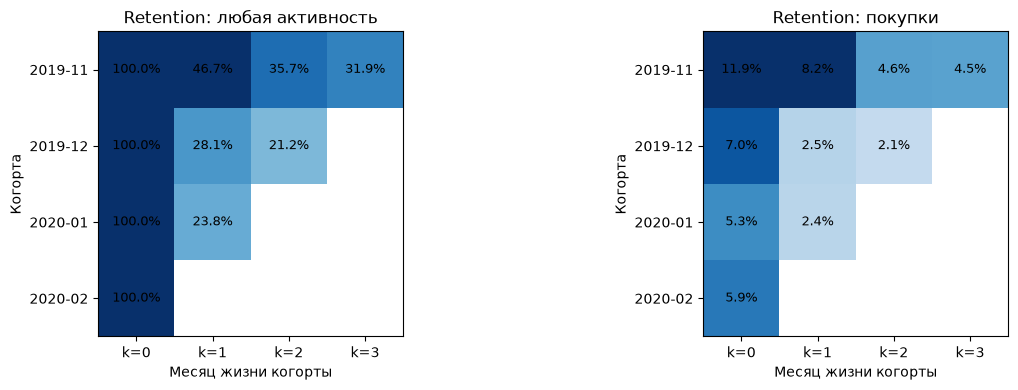

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, r) in zip(axes, [('Retention: любая активность', ret_active),
                                  ('Retention: покупки', ret_buy)]):
    data = r.drop(columns='cohort_size')
    im = ax.imshow(data.values.astype(float), cmap='Blues', vmin=0, vmax=max(0.01, np.nanmax(data.values[:, 1:].astype(float)) if data.shape[1] > 1 else 1))
    ax.set_xticks(range(data.shape[1])); ax.set_xticklabels([f'k={c}' for c in data.columns])
    ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.1%}', ha='center', va='center', fontsize=9)
    ax.set_title(title); ax.set_xlabel('Месяц жизни когорты'); ax.set_ylabel('Когорта')
plt.tight_layout(); plt.show()

In [62]:
n_all = int(client.command("SELECT uniqExact(user_id) FROM shop.events"))
n_excl = int(client.command(
    "SELECT uniqExact(user_id) FROM shop.events "
    "WHERE user_id IN (SELECT user_id FROM shop.excluded_users)"))
n_cohorts = int(ret_active['cohort_size'].sum())
print(f"пользователей в events:        {n_all:,}")
print(f"из них в excluded_users:       {n_excl:,}")
print(f"сумма размеров когорт:         {n_cohorts:,}")
print("совпадает:", n_cohorts == n_all - n_excl)

пользователей в events:        10,723,862
из них в excluded_users:       96
сумма размеров когорт:         10,723,766
совпадает: True


### 6.3 LTV/CAC по каналам привлечения

Выручка рассчитывается по реальным покупкам, тогда как **расходы, маржинальность и сам канал привлечения синтетические** (`shop.user_channels`, `shop.channel_spend`; сценарное допущение: маркетинговый бюджет составляет ≈ 8,75 % выручки без учёта аномальных пользователей). Расчёт выполняет готовое представление `shop.v_channel_unit_economics`, в котором для каждого канала определяются (п. 3.4):

| Показатель | Расчёт в представлении |
|:--|:--|
| `users` | Число пользователей канала в `shop.user_channels` (без `shop.excluded_users`) |
| `spend` | Сумма синтетических расходов канала за весь период |
| `cac` | `spend / users` |
| `revenue` | Сумма `price` покупок (`price > 0`) пользователей канала |
| `gross_margin` | `revenue × avg(gross_margin_rate)` по каналу |
| `ltv` | `gross_margin / users` |
| `ltv_cac` | `ltv / cac` |
| `conversion_to_purchase` | Доля пользователей канала, совершивших хотя бы одну покупку |
| `profit` | `gross_margin − spend` |

Поскольку `users` присутствует и в `ltv`, и в `cac`, отношение `LTV/CAC` тождественно равно `gross_margin / spend` и не зависит от численности канала.

Исключаемые пользователи (п. 2.12: 96 пользователей, 0,2 % событий и пренебрежимо малая доля выручки) практически не влияют на результат: изменения затрагивают лишь `users`, а значит `cac` и `ltv` на доли процента, и не затрагивают `ltv_cac`.

In [63]:
def show(df, fmt):
    out = df.astype(object).copy()
    for col, f in fmt.items():
        out[col] = df[col].map(lambda v, f=f: '' if pd.isna(v) else f.format(v))
    return out

In [64]:
ltv = client.query_df('''
    SELECT channel, users, spend, cac, revenue, gross_margin, ltv, ltv_cac,
           conversion_to_purchase, profit
    FROM shop.v_channel_unit_economics
    ORDER BY ltv_cac DESC
''')
show(ltv, {
    'users': '{:,.0f}', 'spend': '{:,.0f}', 'cac': '{:.2f}', 'revenue': '{:,.0f}',
    'gross_margin': '{:,.0f}', 'ltv': '{:.2f}', 'ltv_cac': '{:.2f}',
    'conversion_to_purchase': '{:.1%}', 'profit': '{:,.0f}',
})


,channel,users,spend,cac,revenue,gross_margin,ltv,ltv_cac,conversion_to_purchase,profit
0,email,"1,199,911","5,480,836",4.57,"240,166,854","67,084,755",55.91,12.24,21.5%,"61,603,919"
1,organic_search,"2,276,081","15,824,200",6.95,"365,825,421","109,534,480",48.12,6.92,17.0%,"93,710,280"
2,referral,"729,145","10,836,328",14.86,"244,022,939","60,862,346",83.47,5.62,35.4%,"50,026,018"
3,paid_search,"3,558,276","43,431,699",12.21,"245,099,834","54,079,557",15.20,1.25,7.3%,"10,647,857"
4,social,"2,960,353","31,795,636",10.74,"119,651,670","23,983,831",8.10,0.75,4.3%,"-7,811,805"


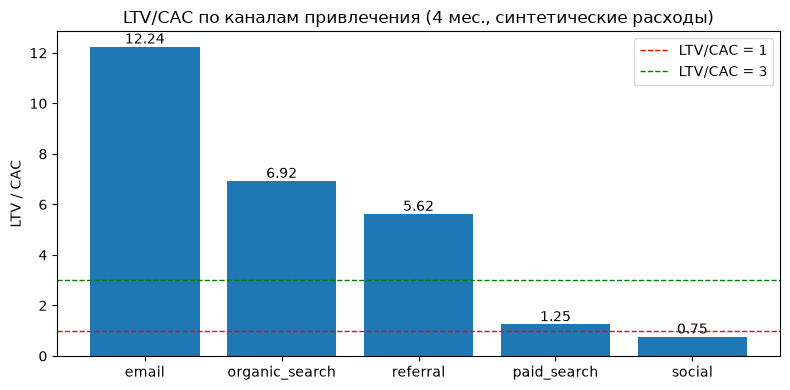

In [66]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(ltv['channel'], ltv['ltv_cac'])
ax.axhline(1, color='red', ls='--', lw=1, label='LTV/CAC = 1')
ax.axhline(3, color='green', ls='--', lw=1, label='LTV/CAC = 3')
ax.bar_label(bars, fmt='%.2f')
ax.set_ylabel('LTV / CAC'); ax.set_title('LTV/CAC по каналам привлечения (4 мес., синтетические расходы)')
ax.legend(); plt.tight_layout(); plt.show()


#### Результаты по LTV/CAC

**LTV/CAC по каналам** (окно наблюдения 4 месяца, синтетические расходы и каналы; аномальные пользователи исключены):

| Канал | Пользователи | Расходы | CAC | LTV | LTV/CAC | Конверсия в покупку | Прибыль | Оценка |
|:--|--:|--:|--:|--:|--:|--:|--:|:--|
| email | 1 199 911 | 5 480 836 | 4,57 | 55,91 | **12,24** | 21,5 % | 61 603 919 | значительно выше ориентира 3 |
| organic_search | 2 276 081 | 15 824 200 | 6,95 | 48,12 | **6,92** | 17,0 % | 93 710 280 | выше ориентира |
| referral | 729 145 | 10 836 328 | 14,86 | 83,47 | **5,62** | 35,4 % | 50 026 018 | выше ориентира |
| paid_search | 3 558 276 | 43 431 699 | 12,21 | 15,20 | **1,25** | 7,3 % | 10 647 857 | окупается на грани безубыточности |
| social | 2 960 353 | 31 795 636 | 10,74 | 8,10 | **0,75** | 4,3 % | −7 811 805 | убыточен: валовая маржа не покрывает расходы |

Сумма пользователей по каналам (10 723 766) совпадает с суммой размеров когорт в п. 6.2.

**Интерпретация.**
- **Три группы каналов.** Каналы email, organic_search и referral окупаются с существенным запасом (LTV/CAC от 5,6 до 12,2). Платные каналы находятся на границе безубыточности (paid_search, 1,25) или ниже неё (social, 0,75; прибыль отрицательна).
- **Структура затрат и отдачи.** Минимальный CAC у email (4,57) сочетается с высокой маржой на пользователя (LTV = 55,91). У referral CAC наибольший (14,86), но его перекрывает наибольший LTV (83,47), обусловленный долей покупателей 35,4 %. Прибыль в абсолютном выражении максимальна у organic_search (93,7 млн) за счёт объёма канала (2,28 млн пользователей).
- **Оговорка о валидности (циркулярность).** Канал назначается пользователю синтетически с вероятностями, зависящими от факта покупки (`pipeline.py`, `user_channels`): покупатели чаще попадают в organic_search, referral и email, не покупатели — в paid_search и social. Следовательно, различия `conversion_to_purchase` по каналам, а вместе с ними `revenue`, `LTV` и ранжирование LTV/CAC, в значительной степени заданы самим правилом назначения, а не поведением реальных каналов. Доли бюджета и маржинальность каналов также заданы константами в `pipeline.py`. Результат демонстрирует метод расчёта и чувствительность к допущениям, но не экономику каналов магазина.
- **Ограничение показателя.** LTV является наблюдаемой за 4 месяца величиной, а не прогнозом; ноябрьская когорта включает ранее привлечённых пользователей (п. 3.6).
- **Практическое следствие** (при условии, что реальная атрибуция даст сопоставимую картину). Социальный канал следует пересмотреть или сократить, paid_search — оптимизировать до порога LTV/CAC ≥ 3, а высвобождаемый бюджет проверять на email и referral с учётом убывающей отдачи малых каналов при масштабировании.
- **Связь с продуктом.** При LTV/CAC выше 3 у магазина имеется запас для оплаты вмешательств (напоминаний, скидок) на брошенных корзинах; предельные затраты на скидку определяются маржой заказа (раздел 1).

---

## 7. Этика

| Вопрос | Комментарий |
|:--|:--|
| **Цель** | Оценить удержание и окупаемость каналов (LTV/CAC) и показать, на каких пользователей и в какой момент имеет смысл направлять триггерные коммуникации. Цель — не профилирование людей, а снижение лишних скидок и рассылок |
| **Согласие** | Данные обезличены и опубликованы владельцем (REES46) для исследовательских и образовательных целей; прямых идентификаторов (имя, email, адрес) нет. В реальном внедрении нужно согласие на обработку и на коммуникации, а также простой отказ от рассылок (opt-out) |
| **Специальные категории** | Демографии, здоровья и других специальных категорий в данных нет. Но `category_code` может косвенно указывать на чувствительные покупки (например, медицинские товары), поэтому такие категории не используем для таргетинга скидок |
| **Передача третьим лицам** | Данные не передаются: ClickHouse и Apache Superset запускаются локально в Docker, внешним сервисам данные не отправляются. Секреты (`.env`) в репозиторий не попадают |
| **Хранение и удаление** | Полные данные лежат только локально (`data/`, `clk_data/`) и исключены из Git (`.gitignore`). Удаление: остановить контейнеры и удалить `clk_data/` и `data/`. В реальном внедрении нужен срок хранения и процедура удаления данных пользователя по запросу |
| **Происхождение и лицензия** | REES46 / Open CDP, Kaggle; источник указан в разделе 2, лицензия — `Data files © Original Authors`, файлы не перепубликуются |
| **Риски и ограничения** | (1) Повторная идентификация по `user_id` и поведению: деанонимизацию не предпринимаем. (2) Персональные скидки могут быть несправедливыми к группам пользователей: нужен контроль критериев и прозрачность. (3) Канал и расходы в треке Б **синтетические**, поэтому выводы по LTV/CAC нельзя выдавать за реальную экономику магазина. (4) Частые напоминания раздражают клиентов: нужен лимит частоты |


---

## 8. Критерии успеха

Целевые значения фиксируются до проведения эксперимента и представляют собой допущения. Базовые значения получены в расчётах разделов 3 и 6 на данных REES46 с исключением аномальных пользователей (п. 3.5).

### 8.1 Целевые показатели

Целевые значения фиксируются до внедрения платформы. Базовые значения получены в расчётах разделов 3 и 6 на данных REES46.

| Метрика | Базовое значение | Целевое значение | Метод проверки |
|:--|:--|:--|:--|
| **Data Quality: Доля ботов** | 0,2% событий | **0% в витринах Gold** (боты исключены из всех расчётов раздела 6) | Проверка: `SELECT count() FROM shop.user_channels WHERE user_id IN (SELECT user_id FROM shop.excluded_users)` → 0 |
| **Data Quality: Дубликаты** (Риск) | 1,05 млн (0,43%) | **0%** (в отчетах) | Проверка через `FINAL` в `shop.events` |
| **Time-to-Insight** (Продукт) | ~2 часа (ручной SQL) | **< 5 минут** (готовый дашборд) | Замер времени от запроса маркетолога до получения графика в Superset |
| **LTV/CAC** (Бизнес) | По каналам от 0,75 (social) до 12,24 (email) | **≥ 3 во всех каналах** (после отключения убыточных) | Пересчёт `shop.v_channel_unit_economics` после реального перераспределения бюджета |

**Метрики внедрения BI-платформы (DAU/WAU дашбордов):**
Успех продукта также оценивается по проценту сотрудников (маркетологов/аналитиков), которые ежедневно используют дашборды Superset. Цель: > 80% целевой аудитории заходят в дашборд хотя бы 1 раз в день.

---

## 9. Репозиторий

Что есть в репозитории и где искать:

| Файл | Назначение |
|:--|:--|
| `README.md` | Задача, откуда данные, как запустить, что получилось |
| `requirements.txt` | Зависимости Python |
| `.gitignore` | Исключает данные (`*.csv`, `data/`, `clk_data/`), секреты (`.env`) и служебные папки |
| `.env.example` | Шаблон настроек без секретов (скопировать в `.env`) |
| `docker-compose.yaml` | запуск инфраструктуры |
| `pipeline.py` | Загрузка данных, синтетические каналы и расходы, когорты, витрины |
| `intro.ipynb` | ноутбук |
